# Test getccFBA_mat
ccFBA as a constraint matrix (python version of `getccFBA_mat` in sybilccFBA): multi-functional enzymes, and only the
cheapest isoenzyme of each reaction (`getGpr1iso`), optionally with protein complex stoichiometry (`cpx_stoich`).

Same settings as `test_ccFBA_mr.ipynb`: iAF1260, RHS=0.27, medval=3600*22.6. As in `simulate_EColi` (R), the matrix is
built once and only the bounds of the irreversible model (`mat['model']`) are changed for each carbon source.

In [1]:
import os
import cobra
import pandas as pd
from getccFBA_mat import getccFBA_mat, solve_ccFBA_mat

In [2]:
modelorg = cobra.io.read_sbml_model(os.path.join('models', 'iAF1260.xml'))
mw = pd.read_csv(os.path.join('data', 'Ecoli_MW.csv'))
kcat = pd.read_csv(os.path.join('data', 'Ecoli_kcat.csv'))

In [3]:
CSList=['EX_glc__D_e', 'EX_glyc_e', 'EX_ac_e', 'EX_fru_e', 'EX_pyr_e', 'EX_gal_e', 'EX_lac__L_e', 'EX_malt_e', 'EX_mal__L_e', 'EX_fum_e', 'EX_xyl__D_e', 'EX_man_e', 'EX_tre_e', 'EX_mnl_e', 'EX_g6p_e', 'EX_succ_e', 'EX_gam_e', 'EX_sbt__D_e', 'EX_glcn_e', 'EX_rib__D_e', 'EX_gsn_e', 'EX_ala__L_e', 'EX_akg_e', 'EX_acgam_e']
msrd=[0.66,0.47,0.29,0.54,0.41,0.24,0.41,0.52,0.55,0.47,0.51,0.35,0.48,0.61,0.78,0.50,0.40,0.48,0.68,0.41,0.37,0.24,0.24,0.61]
CA=[6,3,2,6,3,6,3,12,4,4,5,6,12,6,6,4,6,6,6,5,10,3,5,8]

Reactions with `lower_bound < 0` are split in `<id>_f` and `<id>_b` in the irreversible model, so the uptake of all
carbon sources is opened (lower bound -1000) before building the matrix; each simulation then closes the other carbon
sources (uptake `<id>_b` and secretion `<id>_f`), as the bounds (0, 0) in `test_ccFBA_mr.ipynb`.

In [4]:
for rid in CSList:
    modelorg.reactions.get_by_id(rid).bounds = (-1000.0, 0)
modelorg.reactions.get_by_id('EX_o2_e').lower_bound = -1000.0
modelorg.reactions.get_by_id('ATPM').bounds = (0, 0)

mat = getccFBA_mat(modelorg, Kcat=kcat, MW=mw, verboseMode=1, RHS=0.27, medval=3600*22.6)
mod2 = mat['model']
print(mod2)

Preprocessing isoenzymes ... 


Preparing LP ... 


LP: 5279 rows, 6053 columns (1064 genes, 1783 multi-functional parts, 226 complexes)
<IrrevModel iAF1260: 2980 reactions (598 split), 1668 metabolites>


## Growth on 24 carbon sources

In [5]:
ub0 = mod2.uppbnd.copy()
bmv = []
uptake = []   # actual uptake of the carbon source (mmol/gDW/h) = -flux of its exchange reaction
for cs in CSList:
    mod2.uppbnd[:] = ub0
    for o in CSList:  # close the other carbon sources (uptake '_b' and secretion '_f')
        if o != cs:
            mod2.uppbnd[mod2.react_id.index(o + '_b')] = 0
            mod2.uppbnd[mod2.react_id.index(o + '_f')] = 0
    Res = solve_ccFBA_mat(mat, verboseMode=0)
    bmv.append(Res['obj'])
    uptake.append(-Res['rxnFlx'][cs])
    print(cs, Res['obj'], Res['status'], 'uptake:', uptake[-1])
mod2.uppbnd[:] = ub0

EX_glc__D_e 0.2551998470288176 optimal uptake: 11.125888323369002


EX_glyc_e 0.2564338976655742 optimal uptake: 11.356480534351034


EX_ac_e 0.1804569768528042 optimal uptake: 8.893272182532138


EX_fru_e 0.2502346784776106 optimal uptake: 9.5710430826328


EX_pyr_e 0.21020219286563702 optimal uptake: 6.857558565237145


EX_gal_e 0.24772587745310537 optimal uptake: 10.800047411629215


... (14 outputs left out)

EX_gsn_e 0.28641350900127166 optimal uptake: 8.839085283366192


EX_ala__L_e 0.2114080302529525 optimal uptake: 5.8660550397941815


EX_akg_e 0.23198636877280238 optimal uptake: 6.6235915512869


EX_acgam_e 0.23312216687285797 optimal uptake: 2.195074975192605


In [6]:
from scipy.stats import pearsonr
corr, _ = pearsonr(bmv, msrd)
print(corr)

0.39431130607020975


In [7]:
resDF = pd.DataFrame({'carbon_source': CSList, 'C_atoms': CA, 'measured_growth': msrd,
                      'predicted_growth': bmv, 'uptake': uptake})
resDF['C_uptake'] = resDF['uptake'] * resDF['C_atoms']
resDF

,carbon_source,C_atoms,measured_growth,predicted_growth,uptake,C_uptake
0,EX_glc__D_e,6,0.66,0.255200,11.125888,66.755330
1,EX_glyc_e,3,0.47,0.256434,11.356481,34.069442
2,EX_ac_e,2,0.29,0.180457,8.893272,17.786544
3,EX_fru_e,6,0.54,0.250235,9.571043,57.426258
4,EX_pyr_e,3,0.41,0.210202,6.857559,20.572676
5,EX_gal_e,6,0.24,0.247726,10.800047,64.800284
6,EX_lac__L_e,3,0.41,0.209886,6.684932,20.054797
7,EX_malt_e,12,0.52,0.250115,4.783233,57.398801
8,EX_mal__L_e,4,0.55,0.215257,5.732266,22.929063
9,EX_fum_e,4,0.47,0.215036,5.726388,22.905550


Pearson corr R= 0.394 R^2= 0.155


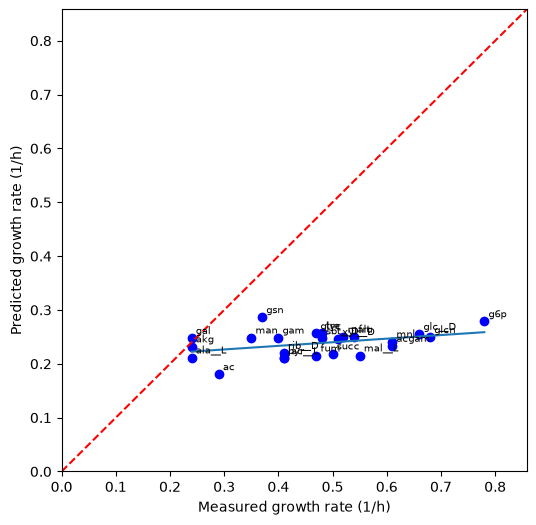

In [8]:
# Scatter plot: measured vs predicted growth rate (red dashed: y=x, blue: linear fit)
import genFuns
genFuns.scatterPlot(msrd, bmv, xlbl='Measured growth rate (1/h)', ylbl='Predicted growth rate (1/h)',
                    labels=[cs[3:-2] for cs in CSList])

## Protein complex stoichiometry
`cpx_stoich_me.csv` (from the R package) gives the number of subunits of each gene in the complexes.

In [9]:
cpx_stoich = pd.read_csv(os.path.join('R', 'sybilccFBA', 'inst', 'extdata', 'cpx_stoich_me.csv'))
mod2.uppbnd[:] = ub0
for o in CSList:
    if o != 'EX_glc__D_e':
        mod2.uppbnd[mod2.react_id.index(o + '_b')] = 0
        mod2.uppbnd[mod2.react_id.index(o + '_f')] = 0
mat_st = getccFBA_mat(modelorg, mod2=mod2, Kcat=kcat, MW=mw, verboseMode=1, RHS=0.27, medval=3600*22.6,
                      cpx_stoich=cpx_stoich)
Res_st = solve_ccFBA_mat(mat_st, verboseMode=0)
print('glucose, with complex stoichiometry:', Res_st['obj'], Res_st['status'])
mat_st['minGiRow'][mat_st['minGiRow']['stoich'] > 1].head()

Preprocessing isoenzymes ... 


Preparing LP ... 


LP: 5287 rows, 6061 columns (1062 genes, 1792 multi-functional parts, 227 complexes)


glucose, with complex stoichiometry: 0.11732985823591971 optimal


,rsn,gsn,rxn,gene,stoich,exprCol,geneCol,rowind,consNames
4,324,3,ARGabcpp,b2306,2.0,5869,4046,4153,min_b2306_ARGabcpp_2
5,1366,3,HISabcpp,b2306,2.0,5952,4047,4154,min_b2306_HISabcpp_2
6,1536,3,LYSabcpp,b2306,2.0,5966,4048,4155,min_b2306_LYSabcpp_2
7,1765,3,ORNabcpp,b2306,2.0,5986,4049,4156,min_b2306_ORNabcpp_2
17,339,14,ASCBptspp,b4193,2.0,5872,2989,4166,min_b4193_ASCBptspp_2
